Basic Classification Demo

In [47]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import SGDClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import precision_recall_curve


In [48]:
df = pd.read_csv('digits_demo.csv')
feature_names = [f'pixel_{i}' for i in range(64)]
X = df[feature_names]
digit_labels = df['digit']
y = digit_labels.eq(5)
print('Table shape:', df.shape)
print('Feature shape:', X.shape)
print('Target values:', sorted(y.unique()))


Table shape: (1797, 65)
Feature shape: (1797, 64)
Target values: [np.False_, np.True_]


Training rows: 1437
Test rows: 360
Training positive rate: 0.102


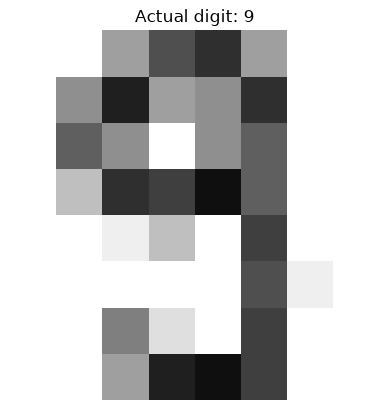

In [49]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print('Training rows:', len(X_train))
print('Test rows:', len(X_test))
print('Training positive rate:', round(y_train.mean(), 3))
image = X_train.iloc[0].to_numpy().reshape(8, 8)
plt.imshow(image, cmap='gray_r', vmin=0, vmax=16)
plt.title(f'Actual digit: {digit_labels.loc[X_train.index[0]]}')
plt.axis('off')
plt.show()


In [50]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
dummy = DummyClassifier(strategy='most_frequent')
dummy_pred = cross_val_predict(dummy, X_train, y_train, cv=cv)
print('Baseline accuracy:', accuracy_score(y_train, dummy_pred))
print('Baseline recall:', recall_score(y_train, dummy_pred))


Baseline accuracy: 0.8983994432846207
Baseline recall: 0.0


In [51]:
model = make_pipeline(
    StandardScaler(),
    SGDClassifier(random_state=42, max_iter=2000, tol=1e-3)
)
model.fit(X_train, y_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('sgdclassifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[bool](2,)","[False, True]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](64,)","['pixel_0','pixel_1','pixel_2',...,'pixel_61','pixel_62','pixel_63']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,64
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [52]:
one_image = X_train.iloc[[0]]
print('Actual is 5:', bool(y_train.iloc[0]))
print('Predicted is 5:', bool(model.predict(one_image)[0]))
print('Decision score:', model.decision_function(one_image)[0])


Actual is 5: False
Predicted is 5: False
Decision score: -64.11740685356077


Accuracy: 0.986
Precision: 0.985
Recall: 0.877
F1: 0.928
[[TN, FP], [FN, TP]]: [[1289, 2], [18, 128]]


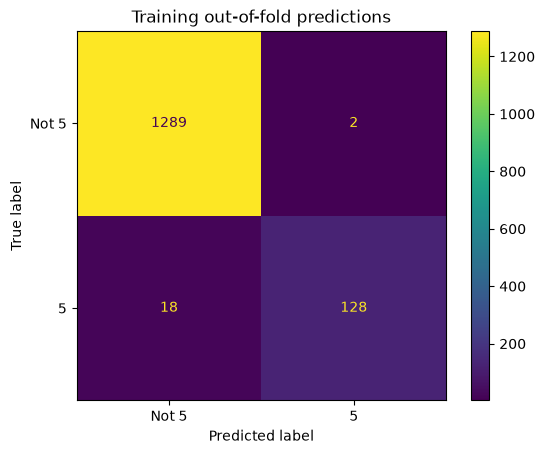

In [53]:
scores = cross_val_predict(
    model, X_train, y_train, cv=cv, method='decision_function'
)
pred_default = scores >= 0

def report(actual, predicted):
    print('Accuracy:', round(accuracy_score(actual, predicted), 3))
    print('Precision:', round(precision_score(
        actual, predicted, zero_division=0), 3))
    print('Recall:', round(recall_score(
        actual, predicted, zero_division=0), 3))
    print('F1:', round(f1_score(actual, predicted, zero_division=0), 3))

report(y_train, pred_default)
cm = confusion_matrix(y_train, pred_default, labels=[False, True])
print('[[TN, FP], [FN, TP]]:', cm.tolist())
ConfusionMatrixDisplay(cm, display_labels=['Not 5', '5']).plot()
plt.title('Training out-of-fold predictions')
plt.show()


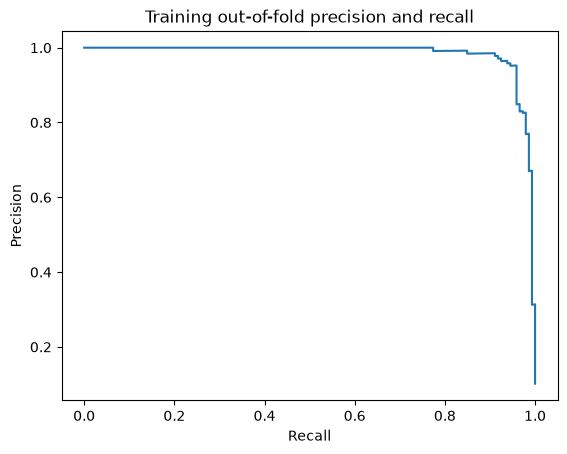

Chosen threshold: -26.26955807662776
Accuracy: 0.991
Precision: 0.952
Recall: 0.959
F1: 0.956


In [54]:
precisions, recalls, thresholds = precision_recall_curve(
    y_train, scores
)
plt.plot(recalls, precisions)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Training out-of-fold precision and recall')
plt.show()

target_precision = 0.95
eligible = np.flatnonzero(precisions[:-1] >= target_precision)
if len(eligible) == 0:
    chosen_threshold = 0.0
    print('Target not reached; retain threshold 0 for this demo.')
else:
    best = eligible[np.argmax(recalls[eligible])]
    chosen_threshold = float(thresholds[best])
print('Chosen threshold:', chosen_threshold)
report(y_train, scores >= chosen_threshold)


In [55]:
# Run this before the final evaluation cell.
for candidate in [0.0, chosen_threshold, chosen_threshold + 10]:
    print('\nThreshold:', candidate)
    report(y_train, scores >= candidate)

# Record your selected threshold and reasoning before testing.
final_threshold = chosen_threshold



Threshold: 0.0
Accuracy: 0.986
Precision: 0.985
Recall: 0.877
F1: 0.928

Threshold: -26.26955807662776
Accuracy: 0.991
Precision: 0.952
Recall: 0.959


F1: 0.956

Threshold: -16.26955807662776
Accuracy: 0.99
Precision: 0.971
Recall: 0.925
F1: 0.947


Accuracy: 0.981
Precision: 0.872
Recall: 0.944
F1: 0.907


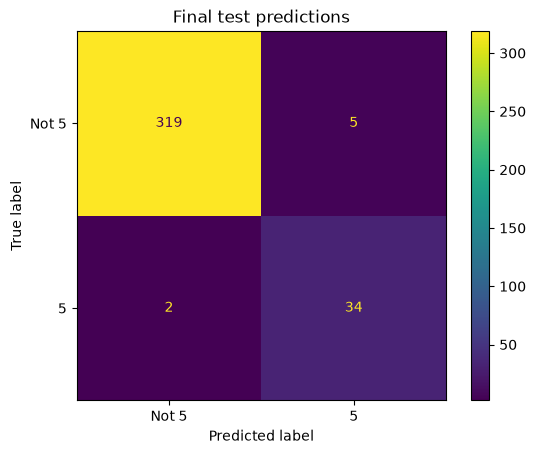

In [56]:
# Run once after model and threshold selection are complete.
model.fit(X_train, y_train)
test_scores = model.decision_function(X_test)
test_predictions = test_scores >= final_threshold
report(y_test, test_predictions)
test_cm = confusion_matrix(y_test, test_predictions, labels=[False, True])
ConfusionMatrixDisplay(test_cm, display_labels=['Not 5', '5']).plot()
plt.title('Final test predictions')
plt.show()


Debrief questions

Why was the baseline accuracy high while its recall was zero?
 Only about 10% of the images are 5s. A model that always says "not 5" is right about 90% of the time. It never finds a single 5, so recall is 0.

Which mistake became less common when you raised the threshold?
 False positives, meaning non-5s labeled as 5s. The model now needs a higher score before it says "5", so precision goes up. The cost is more false negatives (missed 5s), so recall goes down.

Why can a training-validation precision target fail on the test set?
 We picked the threshold by looking at those same labels, so it is tuned to that data and its result is a bit optimistic. The test set is a small sample with different examples. Refitting the model on all training rows can also shift the score scale. So the test precision can land below 0.95.

What would change if we predicted the actual digit instead of a Boolean label?
 The task becomes multiclass, with 10 classes instead of 2. The confusion matrix becomes 10×10. Precision and recall are then reported per digit or averaged. The baseline accuracy would be about 10%. There is no single threshold to tune, because the model picks among 10 scores. SGD handles this by training multiple binary classifiers (one-vs-rest or one-vs-one).